# Benchmarking on human lymph node samples

In [1]:
import scanpy as sc
import pandas as pd
import matplotlib.pyplot as plt


In [ ]:
dataset = 'HLN_D1'
path = f'../results/{dataset}/all_results'
adata = sc.read_h5ad(path + '/' + 'adata_all.h5ad')

In [3]:

list_Seurat = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9,10]
adata.obs['seurat_clusters'] = pd.Categorical(adata.obs['seurat_clusters'],
                                              categories=list_Seurat,
                                              ordered=True)
list_totalVI = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9','10']
adata.obs['leiden_TotalVI'] = pd.Categorical(adata.obs['leiden_TotalVI'],
                                             categories=list_totalVI,
                                             ordered=True)
list_MultiVI = ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9','10']
adata.obs['leiden_MultiVI'] = pd.Categorical(adata.obs['leiden_MultiVI'],
                                             categories=list_MultiVI,
                                             ordered=True)
list_MOFA = [ '1', '2', '3', '4', '5', '6', '7', '8', '9','10','11']
adata.obs['MOFA_clusters'] = pd.Categorical(adata.obs['MOFA_clusters'],
                                            categories=list_MOFA,
                                            ordered=True)
list_STAGATE = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,11]
adata.obs['STAGATE_cluster'] = pd.Categorical(adata.obs['STAGATE_cluster'],
                                              categories=list_STAGATE,
                                              ordered=True)
list_GraphST = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,11]
adata.obs['GraphST_cluster'] = pd.Categorical(adata.obs['GraphST_cluster'],
                                              categories=list_GraphST,
                                              ordered=True)
list_COSMOS = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,11]
adata.obs['COSMOS_cluster'] = pd.Categorical(adata.obs['COSMOS_cluster'],
                                             categories=list_COSMOS,
                                             ordered=True)
list_PRAGA = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,11]
adata.obs['PRAGA_cluster'] = pd.Categorical(adata.obs['PRAGA_cluster'],
                                            categories=list_PRAGA,
                                            ordered=True)

list_miso =  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,11]
adata.obs['miso_cluster'] = pd.Categorical(adata.obs['miso_cluster'],
                                           categories=list_miso,
                                           ordered=True)

list_SpatialGlue =  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,11]
adata.obs['SpatialGlue_cluster'] = pd.Categorical(adata.obs['SpatialGlue_cluster'],
                                                  categories=list_SpatialGlue,
                                                  ordered=True)

list_our =  [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,11]
adata.obs['our_cluster'] = pd.Categorical(adata.obs['our_cluster'],
                                          categories=list_our,
                                          ordered=True)

In [ ]:
import pandas as pd

anno = pd.read_csv(f"../results/{dataset}/annotation.csv", index_col=0)
adata.obs = adata.obs.join(anno)

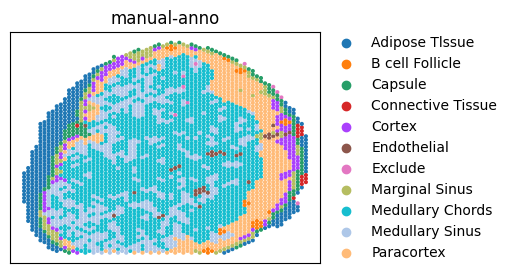

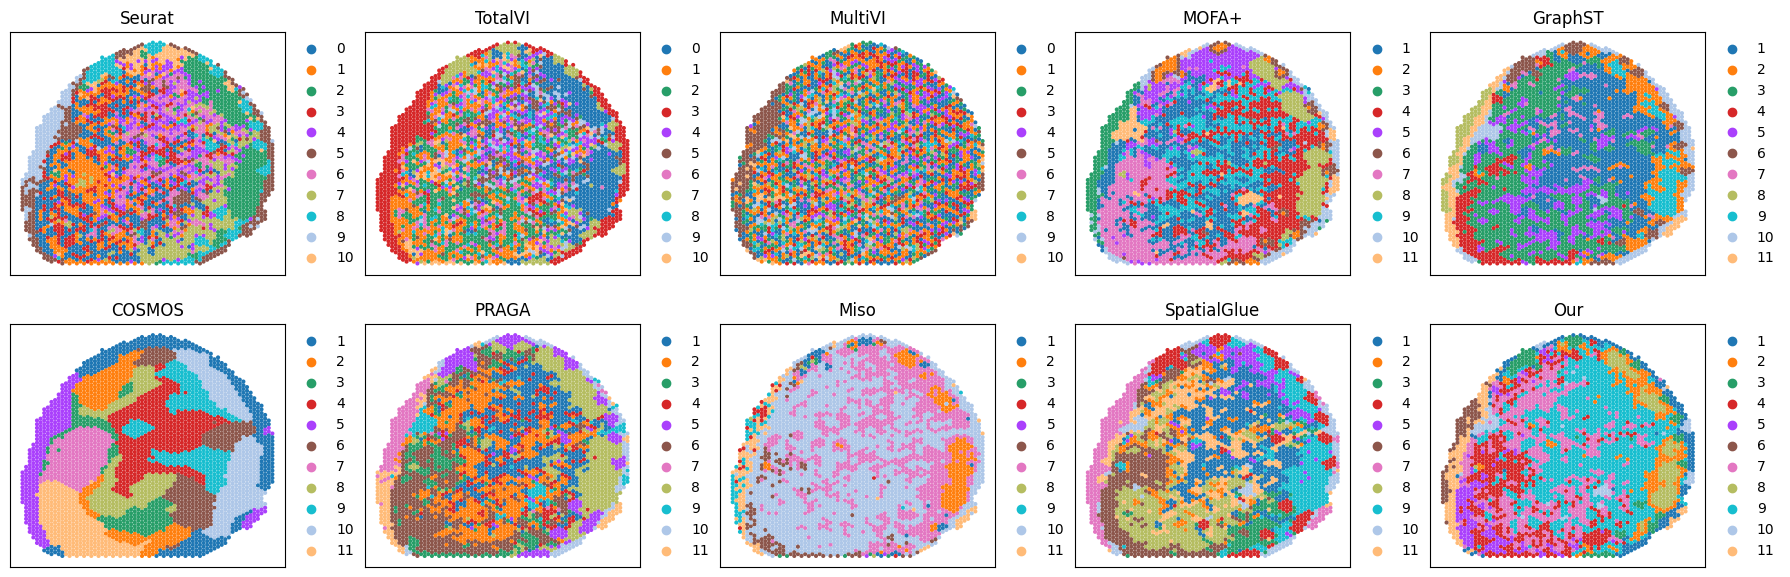

In [5]:

plt.rcParams['font.size'] = 10
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']

s_size = 35
#manual_anno
fig, ax = plt.subplots(figsize=(4, 3))
sc.pl.embedding(adata, basis='spatial', color='manual-anno', title='manual-anno', ax=ax,
                s=s_size, show=False)
ax.set(xlabel='', ylabel='')


fig, ax_list = plt.subplots(2, 5, figsize=(18, 6))
sc.pl.embedding(adata, basis='spatial', color='seurat_clusters', title='Seurat', ax=ax_list[0, 0], s=s_size, show=False)
sc.pl.embedding(adata, basis='spatial', color='leiden_TotalVI', title='TotalVI', ax=ax_list[0, 1], s=s_size, show=False)
sc.pl.embedding(adata, basis='spatial', color='leiden_MultiVI', title='MultiVI', ax=ax_list[0, 2], s=s_size, show=False)
sc.pl.embedding(adata, basis='spatial', color='MOFA_clusters', title='MOFA+', ax=ax_list[0, 3], s=s_size, show=False)

sc.pl.embedding(adata, basis='spatial', color='GraphST_cluster', title='GraphST', ax=ax_list[0, 4], s=s_size,
                show=False)
sc.pl.embedding(adata, basis='spatial', color='COSMOS_cluster', title='COSMOS', ax=ax_list[1, 0], s=s_size, show=False)
sc.pl.embedding(adata, basis='spatial', color='PRAGA_cluster', title='PRAGA', ax=ax_list[1, 1], s=s_size, show=False)
sc.pl.embedding(adata, basis='spatial', color='miso_cluster', title='Miso', ax=ax_list[1, 2], s=s_size, show=False)
sc.pl.embedding(adata, basis='spatial', color='SpatialGlue_cluster', title='SpatialGlue', ax=ax_list[1, 3], s=s_size,
                show=False)
sc.pl.embedding(adata, basis='spatial', color='our_cluster', title='Our', ax=ax_list[1, 4], s=s_size, show=False)

ax_list[0, 0].set_xlabel('')
ax_list[0, 1].set_xlabel('')
ax_list[0, 2].set_xlabel('')
ax_list[0, 3].set_xlabel('')
ax_list[0, 4].set_xlabel('')

ax_list[1, 0].set_xlabel('')
ax_list[1, 1].set_xlabel('')
ax_list[1, 2].set_xlabel('')
ax_list[1, 3].set_xlabel('')
ax_list[1, 4].set_xlabel('')

ax_list[0, 0].set_ylabel('')
ax_list[0, 1].set_ylabel('')
ax_list[0, 2].set_ylabel('')
ax_list[0, 3].set_ylabel('')
ax_list[0, 4].set_ylabel('')

ax_list[1, 0].set_ylabel('')
ax_list[1, 1].set_ylabel('')
ax_list[1, 2].set_ylabel('')
ax_list[1, 3].set_ylabel('')
ax_list[1, 4].set_ylabel('')

plt.tight_layout(w_pad=0.4)


# Comparison of different methods with 6 supervised metrics

In [6]:
def clustering_accuracy(y_true, y_pred):
    from scipy.optimize import linear_sum_assignment
    from sklearn.metrics import accuracy_score
    import numpy as np

    y_true = np.array(y_true, dtype=int)
    y_pred = np.array(y_pred, dtype=int)
    D = max(y_pred.max(), y_true.max()) + 1
    w = np.zeros((D, D), dtype=np.int64)
    for i in range(y_pred.size):
        w[y_pred[i], y_true[i]] += 1
    row_ind, col_ind = linear_sum_assignment(w.max() - w)
    y_pred_aligned = np.array([col_ind[label] for label in y_pred])
    return accuracy_score(y_true, y_pred_aligned)


In [7]:
import pandas as pd
from sklearn.metrics import (
    normalized_mutual_info_score, mutual_info_score, adjusted_mutual_info_score,
    v_measure_score, homogeneity_score, completeness_score,
    adjusted_rand_score, fowlkes_mallows_score
)

list_domain_names = [
    'seurat_clusters', 'leiden_TotalVI', 'leiden_MultiVI', 'MOFA_clusters',
    'GraphST_cluster', 'COSMOS_cluster', 'PRAGA_cluster',
    'miso_cluster', 'SpatialGlue_cluster', 'our_cluster'
]

results = {}

for domain in list_domain_names:
    print(f"\n{domain} :")

    true_labels = adata.obs['manual-anno'].astype('category').cat.codes
    pred_labels = adata.obs[domain].astype('category').cat.codes

    metrics = {
        "Acc": clustering_accuracy(true_labels, pred_labels),
        # "Mutual_Info": mutual_info_score(true_labels, pred_labels),
        "V-measure": v_measure_score(true_labels, pred_labels),
        "Homogeneity": homogeneity_score(true_labels, pred_labels),
        "Completeness": completeness_score(true_labels, pred_labels),
        "NMI": normalized_mutual_info_score(true_labels, pred_labels,average_method="geometric"),
        "AMI": adjusted_mutual_info_score(true_labels, pred_labels),
        "FMI": fowlkes_mallows_score(true_labels, pred_labels),
        "ARI": adjusted_rand_score(true_labels, pred_labels),
    }

    for k, v in metrics.items():
        print(f"{k:<15}: {v:.10f}")

    results[domain] = metrics


df_results = pd.DataFrame(results).T



seurat_clusters :
Acc            : 0.3343256922
V-measure      : 0.3112966330
Homogeneity    : 0.3704607086
Completeness   : 0.2684276501
NMI            : 0.3153440938
AMI            : 0.3058262667
FMI            : 0.3067669088
ARI            : 0.1520426637

leiden_TotalVI :
Acc            : 0.3733253945
V-measure      : 0.2653563065
Homogeneity    : 0.3122874979
Completeness   : 0.2306880445
NMI            : 0.2684045309
AMI            : 0.2594562562
FMI            : 0.2912594238
ARI            : 0.1315924410

leiden_MultiVI :
Acc            : 0.2283417684
V-measure      : 0.1255545076
Homogeneity    : 0.1427496870
Completeness   : 0.1120565297
NMI            : 0.1264754306
AMI            : 0.1183387138
FMI            : 0.2247157025
ARI            : 0.0398088271

MOFA_clusters :
Acc            : 0.3617147961
V-measure      : 0.3039389644
Homogeneity    : 0.3464576065
Completeness   : 0.2707156710
NMI            : 0.3062539852
AMI            : 0.2982229584
FMI            : 0.340391723

Text(0, 0.5, 'Value')

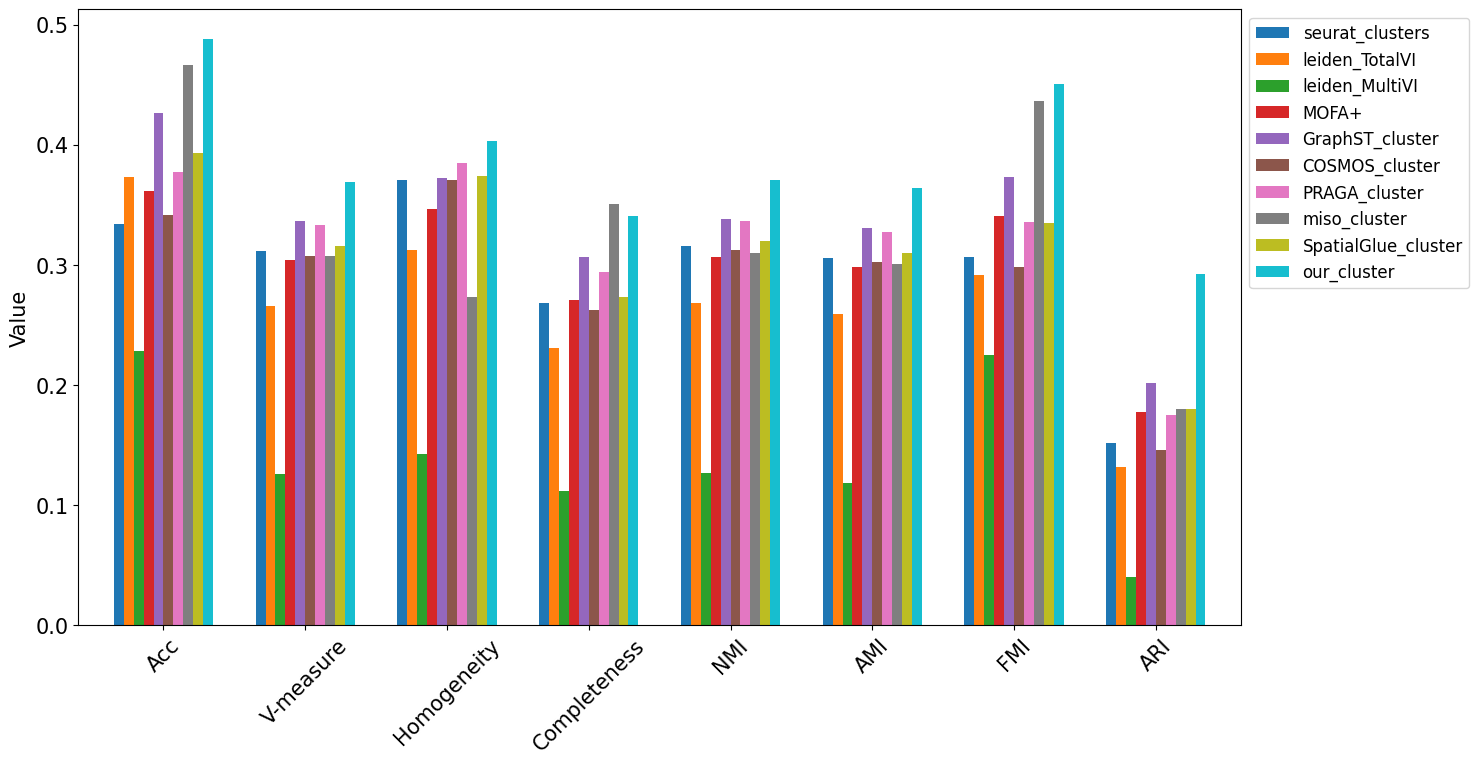

In [8]:
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (15, 8)
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 15

res = df_results.rename(index={'MOFA_clusters': 'MOFA+'}).copy()

res.T.plot(kind='bar', width=0.7)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1), fontsize=12)
plt.xticks(rotation=45)
plt.ylabel('Value')
